# Notebook 13: Reproducibility across participants and rank selection

This notebook answers three reviewer points that share one underlying question — whether the
five-component solution and the choice of *k* are trustworthy.

| Point | Request | Addressed in |
|---|---|---|
| **R1 #2** | Initialisation stability demonstrates optimisation stability, not reproducibility across participants or datasets | Part A |
| **R2 #2** | Assess reproducibility across participants (split-half or bootstrap resampling) | Part A |
| **R2 #3** | Justify *k* among 3, 4, 5, 6; report the omnibus and per-component sex results at each *k*; match components across *k* to show which persist, split or merge | Part B |
| **R2 #1** (part) | The two decompositions are not applied under the same conditions: *k* was selected only for NMF and imposed on PCA, and stability, loadings and interpretation are reported only for NMF | Parts A3, B5 and C |

**Part A** resamples participants rather than initialisations, and measures three things:

1. *Component recovery* — fit NMF on half the cohort, match the resulting components to the
   published solution by cosine similarity, and ask how well each published component is
   recovered when half the participants are withheld.
2. *Out-of-sample replication of the sex association* — the stronger test. Components are
   fitted on one half only; the held-out half is then projected onto those components by
   non-negative least squares, and the sex association is tested in participants who
   contributed nothing to the decomposition.
3. *Bootstrap* — resampling with replacement, giving a sampling distribution for both
   component recovery and the per-component sex effect sizes.

**Part B** refits the pipeline at k = 3, 4, 5 and 6, matches every solution against the
published k = 5 components in both directions, and re-runs the full 17-variable omnibus screen
and the per-component sex follow-up at each *k*.

### Notes on method choices

- The split-half analysis **re-derives the log / winsorisation / min–max transform inside each
  training half** rather than reusing the whole-cohort transform, so no scaling information
  leaks from held-out participants. A reduced sensitivity run reusing the whole-cohort
  transform is reported alongside it.
- Part B is where an unwelcome result could appear. If the two sex-associated components exist
  only at k = 5, that needs to be known before the response letter is written, not after. The
  notebook reports it either way.

### Inputs (all produced by notebooks 01–02)

`outputs/feature_matrix.csv`, `outputs/feature_matrix_raw.csv`, `outputs/metadata.csv`,
`outputs/nmf_H.csv`, `outputs/nmf_W.csv`, `outputs/posthoc_per_component.csv`,
`outputs/omnibus_results.csv`

### Outputs

CSVs: `nb13_splithalf_recovery.csv`, `nb13_splithalf_oos_sex.csv`,
`nb13_splithalf_sensitivity.csv`, `nb13_bootstrap_recovery.csv`,
`nb13_bootstrap_sex_effects.csv`, `nb13_rank_sweep_match.csv`, `nb13_rank_sweep_omnibus.csv`,
`nb13_rank_sweep_posthoc_sex.csv`; and for the basis comparison
`nb13_pca_splithalf_recovery.csv`, `nb13_pca_splithalf_oos_sex.csv`,
`nb13_pca_bootstrap.csv`, `nb13_pca_rank_sweep_omnibus.csv`,
`nb13_pca_rank_sweep_posthoc_sex.csv`, `nb13_basis_comparison_by_k.csv`,
`nb13_basis_comparison_recovery.csv`

Figures: `nb13_fig_recovery.png`, `nb13_fig_oos_sex.png`, `nb13_fig_rank_match.png`,
`nb13_fig_rank_sex.png`, `nb13_fig_basis_comparison.png` — all at 300 dpi

### Re-running

The non-negative results are unchanged from the previous version: the same seeds,
the same splits and the same solver settings, so Parts A and B reproduce what you
already have. Everything new sits in Parts A3, B5 and C, which add roughly 25
minutes, almost all of it the PCA permutation sweep. Set `RUN_PCA_COMPARISON` to
False to skip them.

Summary: `nb13_summary.txt`

## Setup

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment, nnls
from sklearn.decomposition import NMF, PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# --- NMF settings: identical to Notebook 02, do not change ---
MAX_ITER = 500
TOL = 1e-4
RANDOM_SEED_BASE = 42
N_INIT_FULL = 50          # initialisations per k on the full cohort (as in Notebook 02)
PUBLISHED_K = 5

# --- Part A: participant-level reproducibility ---
N_SPLITS = 200            # split-half repetitions; each yields two fit/test directions
N_SPLITS_SENS = 50        # repetitions for the reused-transform sensitivity run
N_BOOT = 500              # bootstrap resamples
N_INIT_SUB = 5            # initialisations per subsample fit; lowest-error fit retained
RESAMPLE_SEED = 2026

# --- Part B: rank selection ---
K_GRID = [3, 4, 5, 6]
N_PERMUTATIONS = 5000     # as in Notebook 04
FDR_ALPHA = 0.05
PERM_SEED = 42

# --- Principal component comparison (Reviewer 2, point 1) ---
RUN_PCA_COMPARISON = True   # set False to skip Parts A3, B5 and C
PCA_SEED = 0               # as in Notebook 09

# --- Winsorisation percentiles: must match Notebook 01 ---
LOWER_PCT, UPPER_PCT = 2.5, 97.5

# --- Metadata column holding sex ---
SEX_COL = "Gender"

print("Part A:", N_SPLITS, "split-half repetitions x 2 directions,", N_BOOT, "bootstrap resamples")
print("Part B: k =", K_GRID, "|", N_PERMUTATIONS, "permutations x 17 variables x",
      len(K_GRID), "values of k")
print()
print("Expected runtime: Part A roughly 5-12 min. Part B is dominated by the permutation")
print("sweep, roughly 20-60 min depending on the machine; it can be run on its own.")

Part A: 200 split-half repetitions x 2 directions, 500 bootstrap resamples
Part B: k = [3, 4, 5, 6] | 5000 permutations x 17 variables x 4 values of k

Expected runtime: Part A roughly 5-12 min. Part B is dominated by the permutation
sweep, roughly 20-60 min depending on the machine; it can be run on its own.


## Load inputs and check alignment

In [2]:
feature_matrix = pd.read_csv(OUTPUT_DIR / "feature_matrix.csv", index_col="participant_id")
feature_matrix_raw = pd.read_csv(OUTPUT_DIR / "feature_matrix_raw.csv", index_col="participant_id")
metadata = (pd.read_csv(OUTPUT_DIR / "metadata.csv")
            .set_index("participant_id")
            .reindex(feature_matrix.index))
H_ref = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
W_ref = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")

assert set(feature_matrix_raw.columns) == set(feature_matrix.columns), "raw/scaled feature mismatch"
feature_matrix_raw = feature_matrix_raw.loc[feature_matrix.index, feature_matrix.columns]
assert (feature_matrix.index == metadata.index).all(), "metadata not aligned to feature matrix"
assert (W_ref.index == feature_matrix.index).all(), "published W not aligned to feature matrix"
assert list(H_ref.columns) == list(feature_matrix.columns), "published H columns not aligned"

COMP_LABELS = list(H_ref.index)
H_REF_ARR = H_ref.values
PIDS = feature_matrix.index.to_numpy()
N = len(PIDS)

print(f"Feature matrix: {feature_matrix.shape}")
print(f"Published H:    {H_ref.shape}  components: {COMP_LABELS}")
print(f"Participants:   {N}")

Feature matrix: (86, 350)
Published H:    (5, 350)  components: ['comp_1', 'comp_2', 'comp_3', 'comp_4', 'comp_5']
Participants:   86


In [3]:
raw_sex = metadata[SEX_COL].astype(str).str.strip().str.upper().str[0]
if not set(raw_sex.dropna().unique()) <= {"M", "F"}:
    raise ValueError(
        f"Could not read {SEX_COL!r} as M/F. Found: "
        f"{sorted(metadata[SEX_COL].dropna().unique())}. "
        "Set SEX_COL, or map the coding to 'M'/'F' before continuing."
    )
SEX = raw_sex.values
print(f"Sex: {(SEX == 'M').sum()} male, {(SEX == 'F').sum()} female")

PUBLISHED_EFFECTS = pd.read_csv(OUTPUT_DIR / "posthoc_per_component.csv")
PUBLISHED_EFFECTS = (PUBLISHED_EFFECTS[PUBLISHED_EFFECTS["variable"] == SEX_COL]
                     .set_index("component"))
print()
print("Published per-component sex effects (positive = higher in female participants):")
print(PUBLISHED_EFFECTS[["effect_size", "p_raw", "p_fdr"]].round(4).to_string())

Sex: 44 male, 42 female

Published per-component sex effects (positive = higher in female participants):
           effect_size   p_raw   p_fdr
component                             
comp_1          0.5768  0.0000  0.0000
comp_4         -0.3144  0.0122  0.0304
comp_2          0.1331  0.2898  0.4830
comp_5         -0.0574  0.6498  0.7523
comp_3          0.0400  0.7523  0.7523


## Helper functions

`preprocess_array` replicates the Notebook 01 transform (log1p, per-feature winsorisation,
per-feature min–max to [0, 1]) but lets the transform parameters be derived from a subset of
rows and then applied to all of them, which is what makes a leak-free split-half possible.
The cell after it verifies the replication against the saved `feature_matrix.csv`.

In [4]:
def preprocess_array(raw, fit_rows=None, lower_pct=LOWER_PCT, upper_pct=UPPER_PCT):
    """Notebook 01 transform: log1p -> winsorise -> min-max to [0, 1].

    Transform parameters are derived from `fit_rows` (all rows if None) and applied to every
    row. Rows outside the fitting set are clipped into [0, 1] so the matrix stays
    non-negative, as NMF requires.
    """
    logged = np.log1p(np.asarray(raw, dtype=float))
    fit = logged if fit_rows is None else logged[fit_rows]
    lo = np.percentile(fit, lower_pct, axis=0)
    hi = np.percentile(fit, upper_pct, axis=0)
    wins = np.clip(logged, lo, hi)
    wins_fit = wins if fit_rows is None else wins[fit_rows]
    fmin, fmax = wins_fit.min(axis=0), wins_fit.max(axis=0)
    span = fmax - fmin
    span[span == 0] = 1.0
    return np.clip((wins - fmin) / span, 0.0, 1.0)


def cosine_similarity_matrix(A, B):
    """Pairwise cosine similarity between rows of A and rows of B; shape (n_A, n_B)."""
    A_norm = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    B_norm = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return A_norm @ B_norm.T


def match_to_reference(H_new, H_ref_arr=None):
    """Hungarian-match rows of H_new to rows of the reference H.

    Returns (cosine per reference component, index into H_new per reference component).
    Reference components left unmatched, when H_new has fewer rows, get NaN and -1.
    """
    if H_ref_arr is None:
        H_ref_arr = H_REF_ARR
    sim = cosine_similarity_matrix(H_ref_arr, H_new)
    row, col = linear_sum_assignment(-sim)
    cos = np.full(H_ref_arr.shape[0], np.nan)
    idx = np.full(H_ref_arr.shape[0], -1, dtype=int)
    cos[row] = sim[row, col]
    idx[row] = col
    return cos, idx


def fit_nmf_best(X, k, n_init, seed_base):
    """Fit NMF n_init times, returning the lowest-reconstruction-error solution.

    This matches the selection rule used for the published model in Notebook 02.
    """
    best = None
    for i in range(n_init):
        model = NMF(n_components=k, init="random", random_state=seed_base + i,
                    max_iter=MAX_ITER, tol=TOL, beta_loss="frobenius", solver="cd")
        W = model.fit_transform(X)
        if best is None or model.reconstruction_err_ < best[2]:
            best = (W, model.components_, model.reconstruction_err_)
    return best


def project_nnls(X, H):
    """Solve min_w ||x - wH||_2 subject to w >= 0 for each row of X.

    This is the NMF transform step with H held fixed: it assigns component loadings to
    participants who contributed nothing to the decomposition.
    """
    A = H.T
    out = np.zeros((X.shape[0], H.shape[0]))
    for i in range(X.shape[0]):
        out[i], _ = nnls(A, X[i])
    return out


def rb_female_higher(loadings, sex_arr):
    """Mann-Whitney rank-biserial correlation and two-sided p-value.

    Signed so that positive means higher in female participants, matching the convention in
    Notebook 05 and in the manuscript: the U statistic is taken on the male group.
    """
    loadings = np.asarray(loadings, dtype=float)
    f = loadings[sex_arr == "F"]
    m = loadings[sex_arr == "M"]
    if len(f) < 3 or len(m) < 3:
        return np.nan, np.nan
    if np.allclose(loadings, loadings[0]):
        return 0.0, 1.0
    u, p = stats.mannwhitneyu(m, f, alternative="two-sided")
    return float(1 - (2 * u) / (len(m) * len(f))), float(p)


def fit_pca(X, k, seed=PCA_SEED):
    """Fit PCA and return (scores, loadings, mean). Deterministic: unlike NMF there
    is no initialisation to vary, which is why cross-initialisation stability has no
    counterpart in this basis."""
    model = PCA(n_components=k, random_state=seed).fit(X)
    return model.transform(X), model.components_, model.mean_


def match_to_reference_signed(H_new, H_ref_arr):
    """Match a signed basis to a reference, ignoring sign.

    A principal axis is identified only up to sign: negating both the axis and its
    scores leaves the factorisation unchanged. Matching therefore uses the absolute
    cosine, and the sign needed to align each match is returned so that effect
    directions can be compared. The non-negative basis needs no such step, which is
    the asymmetry reported under Reviewer 1's seventh point.
    """
    sim = cosine_similarity_matrix(H_ref_arr, H_new)
    row, col = linear_sum_assignment(-np.abs(sim))
    cos = np.full(H_ref_arr.shape[0], np.nan)
    idx = np.full(H_ref_arr.shape[0], -1, dtype=int)
    sgn = np.ones(H_ref_arr.shape[0])
    cos[row] = np.abs(sim[row, col])
    idx[row] = col
    sgn[row] = np.where(sim[row, col] >= 0, 1.0, -1.0)
    return cos, idx, sgn


def project_pca(X, H, mean):
    """Project rows of X onto fixed principal axes, centred on the training mean."""
    return (X - mean) @ H.T

In [5]:
check = preprocess_array(feature_matrix_raw.values)
max_dev = np.abs(check - feature_matrix.values).max()
print(f"Max deviation from saved feature_matrix.csv: {max_dev:.2e}")
if max_dev > 1e-6:
    print()
    print("WARNING: the replicated transform does not match the saved matrix. Check")
    print("LOWER_PCT/UPPER_PCT and whether Notebook 01 dropped any participant after")
    print("scaling. The split-half results below depend on this replication.")
else:
    print("Transform replication verified.")

Max deviation from saved feature_matrix.csv: 5.55e-16
Transform replication verified.


## Part A1 — Split-half component recovery and out-of-sample sex replication

Each repetition splits the cohort into two halves, stratified by sex so that both halves can
support a sex test. For each direction of each split:

1. the transform is derived on the training half and applied to both halves;
2. NMF (k = 5) is fitted on the training half, best of `N_INIT_SUB` initialisations;
3. the resulting components are Hungarian-matched to the published components;
4. the held-out half is projected onto the training half's components by non-negative least
   squares, and the sex association is tested on those held-out loadings.

Step 4 is the part that no amount of initialisation stability could have provided.

In [6]:
def stratified_half(sex_arr, rng):
    """Split row indices into two halves, stratified by sex."""
    first = []
    for group in ("M", "F"):
        gi = rng.permutation(np.where(sex_arr == group)[0])
        first.extend(gi[: len(gi) // 2])
    first = np.array(sorted(first))
    second = np.array(sorted(set(range(len(sex_arr))) - set(first)))
    return first, second


def run_split_half(n_splits, refit_transform, seed, label):
    """Split-half component recovery and out-of-sample sex test.

    refit_transform=True derives the log/winsorise/min-max transform inside the training half
    (no leakage); False reuses the whole-cohort transform from Notebook 01.
    """
    rng = np.random.default_rng(seed)
    rows_rec, rows_oos = [], []
    t0 = time.time()
    for s in range(n_splits):
        ia, ib = stratified_half(SEX, rng)
        for direction, (i_fit, i_test) in (("1->2", (ia, ib)), ("2->1", (ib, ia))):
            if refit_transform:
                X_all = preprocess_array(feature_matrix_raw.values, fit_rows=i_fit)
            else:
                X_all = feature_matrix.values
            W_fit, H_fit, err = fit_nmf_best(
                X_all[i_fit], PUBLISHED_K, N_INIT_SUB, RANDOM_SEED_BASE + 1000 * s
            )
            cos, idx = match_to_reference(H_fit)
            W_test = project_nnls(X_all[i_test], H_fit)
            sex_test = SEX[i_test]
            for ci, lab in enumerate(COMP_LABELS):
                rows_rec.append({"analysis": label, "split": s, "direction": direction,
                                 "ref_component": lab, "cosine": cos[ci],
                                 "n_fit": len(i_fit), "recon_error": err})
                r, p = rb_female_higher(W_test[:, idx[ci]], sex_test)
                rows_oos.append({"analysis": label, "split": s, "direction": direction,
                                 "ref_component": lab, "matched_cosine": cos[ci],
                                 "rank_biserial": r, "p_raw": p,
                                 "n_female": int((sex_test == "F").sum()),
                                 "n_male": int((sex_test == "M").sum())})
        if (s + 1) % 25 == 0:
            print(f"  {label}: {s + 1}/{n_splits} splits ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows_rec), pd.DataFrame(rows_oos)


print("Primary split-half run (transform refitted within each training half):")
recovery_df, oos_df = run_split_half(N_SPLITS, True, RESAMPLE_SEED, "refit_transform")
recovery_df.to_csv(OUTPUT_DIR / "nb13_splithalf_recovery.csv", index=False)
oos_df.to_csv(OUTPUT_DIR / "nb13_splithalf_oos_sex.csv", index=False)
print()
print(f"Saved {len(recovery_df)} recovery rows and {len(oos_df)} out-of-sample rows")

Primary split-half run (transform refitted within each training half):
  refit_transform: 25/200 splits (8s)
  refit_transform: 50/200 splits (15s)
  refit_transform: 75/200 splits (22s)
  refit_transform: 100/200 splits (31s)
  refit_transform: 125/200 splits (39s)
  refit_transform: 150/200 splits (48s)
  refit_transform: 175/200 splits (56s)
  refit_transform: 200/200 splits (65s)

Saved 2000 recovery rows and 2000 out-of-sample rows


In [7]:
rec_summary = (recovery_df.groupby("ref_component")["cosine"]
               .agg(median="median",
                    q25=lambda s: s.quantile(0.25),
                    q75=lambda s: s.quantile(0.75),
                    minimum="min",
                    frac_ge_090=lambda s: (s >= 0.90).mean(),
                    frac_ge_080=lambda s: (s >= 0.80).mean())
               .reindex(COMP_LABELS))
print("Split-half component recovery (cosine to the published component):")
print(rec_summary.round(3).to_string())

Split-half component recovery (cosine to the published component):
               median    q25    q75  minimum  frac_ge_090  frac_ge_080
ref_component                                                         
comp_1          0.896  0.849  0.934    0.588        0.472        0.865
comp_2          0.874  0.826  0.917    0.617        0.340        0.862
comp_3          0.878  0.817  0.922    0.498        0.402        0.798
comp_4          0.956  0.926  0.973    0.716        0.840        0.975
comp_5          0.963  0.945  0.974    0.760        0.945        0.998


In [8]:
def oos_summary_table(df):
    """Summarise out-of-sample sex effects per published component."""
    g = df.groupby("ref_component")
    out = pd.DataFrame({
        "median_r": g["rank_biserial"].median(),
        "q25_r": g["rank_biserial"].quantile(0.25),
        "q75_r": g["rank_biserial"].quantile(0.75),
        "frac_p_lt_05": g["p_raw"].apply(lambda s: (s < 0.05).mean()),
    })
    pub = PUBLISHED_EFFECTS["effect_size"]
    out["published_r"] = pub.reindex(out.index)
    same = []
    for c in out.index:
        if c in pub.index and not np.isnan(pub[c]):
            vals = df.loc[df["ref_component"] == c, "rank_biserial"]
            same.append(float((np.sign(vals) == np.sign(pub[c])).mean()))
        else:
            same.append(np.nan)
    out["frac_same_direction"] = same
    return out.reindex(COMP_LABELS)


oos_summary = oos_summary_table(oos_df)
print("Out-of-sample sex association in held-out halves")
print("(positive = higher in females; direction judged against the published effect):")
print(oos_summary.round(3).to_string())

Out-of-sample sex association in held-out halves
(positive = higher in females; direction judged against the published effect):
               median_r  q25_r  q75_r  frac_p_lt_05  published_r  frac_same_direction
ref_component                                                                        
comp_1            0.420  0.274  0.528         0.648        0.577                0.948
comp_2            0.201  0.029  0.356         0.260        0.133                0.788
comp_3            0.135 -0.020  0.284         0.118        0.040                0.725
comp_4           -0.208 -0.310 -0.116         0.145       -0.314                0.942
comp_5           -0.036 -0.134  0.065         0.010       -0.057                0.592


### Sensitivity: whole-cohort transform reused instead of refitted

In [9]:
print("Sensitivity run (whole-cohort transform reused, so scaling information leaks):")
rec_sens, oos_sens = run_split_half(N_SPLITS_SENS, False, RESAMPLE_SEED, "shared_transform")
pd.concat([rec_sens, oos_sens], axis=0, ignore_index=True).to_csv(
    OUTPUT_DIR / "nb13_splithalf_sensitivity.csv", index=False)

comparison = pd.DataFrame({
    "refit_median_cosine": recovery_df.groupby("ref_component")["cosine"].median(),
    "reused_median_cosine": rec_sens.groupby("ref_component")["cosine"].median(),
    "refit_median_oos_r": oos_df.groupby("ref_component")["rank_biserial"].median(),
    "reused_median_oos_r": oos_sens.groupby("ref_component")["rank_biserial"].median(),
}).reindex(COMP_LABELS)
print()
print("Refitted vs reused transform:")
print(comparison.round(3).to_string())

Sensitivity run (whole-cohort transform reused, so scaling information leaks):
  shared_transform: 25/50 splits (10s)
  shared_transform: 50/50 splits (18s)

Refitted vs reused transform:
               refit_median_cosine  reused_median_cosine  refit_median_oos_r  reused_median_oos_r
ref_component                                                                                    
comp_1                       0.896                 0.906               0.420                0.412
comp_2                       0.874                 0.884               0.201                0.234
comp_3                       0.878                 0.877               0.135                0.177
comp_4                       0.956                 0.955              -0.208               -0.248
comp_5                       0.963                 0.966              -0.036               -0.028


## Part A2 — Bootstrap resampling of participants

Resamples with replacement. Each resample is transformed on its own rows, decomposed at
k = 5, and matched to the published components. The in-sample sex effect for each matched
component gives a bootstrap sampling distribution for the published effect sizes.

In [10]:
rng_boot = np.random.default_rng(RESAMPLE_SEED + 1)
boot_rec, boot_sex = [], []
t0 = time.time()
for b in range(N_BOOT):
    take = rng_boot.integers(0, N, N)
    sex_b = SEX[take]
    if (sex_b == "M").sum() < 5 or (sex_b == "F").sum() < 5:
        continue
    X_b = preprocess_array(feature_matrix_raw.values[take])
    W_b, H_b, err_b = fit_nmf_best(X_b, PUBLISHED_K, N_INIT_SUB,
                                   RANDOM_SEED_BASE + 7000 + 13 * b)
    cos, idx = match_to_reference(H_b)
    for ci, lab in enumerate(COMP_LABELS):
        boot_rec.append({"boot": b, "ref_component": lab, "cosine": cos[ci],
                         "n_unique": int(len(np.unique(take))), "recon_error": err_b})
        r, p = rb_female_higher(W_b[:, idx[ci]], sex_b)
        boot_sex.append({"boot": b, "ref_component": lab, "matched_cosine": cos[ci],
                         "rank_biserial": r, "p_raw": p})
    if (b + 1) % 50 == 0:
        print(f"  {b + 1}/{N_BOOT} resamples ({time.time() - t0:.0f}s)")

boot_rec_df = pd.DataFrame(boot_rec)
boot_sex_df = pd.DataFrame(boot_sex)
boot_rec_df.to_csv(OUTPUT_DIR / "nb13_bootstrap_recovery.csv", index=False)
boot_sex_df.to_csv(OUTPUT_DIR / "nb13_bootstrap_sex_effects.csv", index=False)
print()
print(f"{boot_rec_df['boot'].nunique()} usable resamples")

  50/500 resamples (15s)
  100/500 resamples (28s)
  150/500 resamples (42s)
  200/500 resamples (56s)
  250/500 resamples (70s)
  300/500 resamples (83s)
  350/500 resamples (99s)
  400/500 resamples (114s)
  450/500 resamples (128s)
  500/500 resamples (142s)

500 usable resamples


In [11]:
boot_summary = pd.DataFrame({
    "median_cosine": boot_rec_df.groupby("ref_component")["cosine"].median(),
    "cosine_q025": boot_rec_df.groupby("ref_component")["cosine"].quantile(0.025),
    "frac_cosine_ge_090": boot_rec_df.groupby("ref_component")["cosine"].apply(
        lambda s: (s >= 0.90).mean()),
    "median_r": boot_sex_df.groupby("ref_component")["rank_biserial"].median(),
    "r_ci_lo": boot_sex_df.groupby("ref_component")["rank_biserial"].quantile(0.025),
    "r_ci_hi": boot_sex_df.groupby("ref_component")["rank_biserial"].quantile(0.975),
}).reindex(COMP_LABELS)
boot_summary["r_ci_excludes_0"] = (boot_summary["r_ci_lo"] > 0) | (boot_summary["r_ci_hi"] < 0)
print("Bootstrap component recovery and sex effect sizes (percentile 95% intervals):")
print(boot_summary.round(3).to_string())

Bootstrap component recovery and sex effect sizes (percentile 95% intervals):
               median_cosine  cosine_q025  frac_cosine_ge_090  median_r  r_ci_lo  r_ci_hi  r_ci_excludes_0
ref_component                                                                                             
comp_1                 0.888        0.697               0.414     0.386   -0.142    0.683            False
comp_2                 0.864        0.715               0.252     0.159   -0.253    0.597            False
comp_3                 0.849        0.644               0.238     0.034   -0.396    0.432            False
comp_4                 0.947        0.788               0.810    -0.233   -0.511    0.041            False
comp_5                 0.955        0.843               0.894    -0.067   -0.371    0.242            False


### Figures for Part A

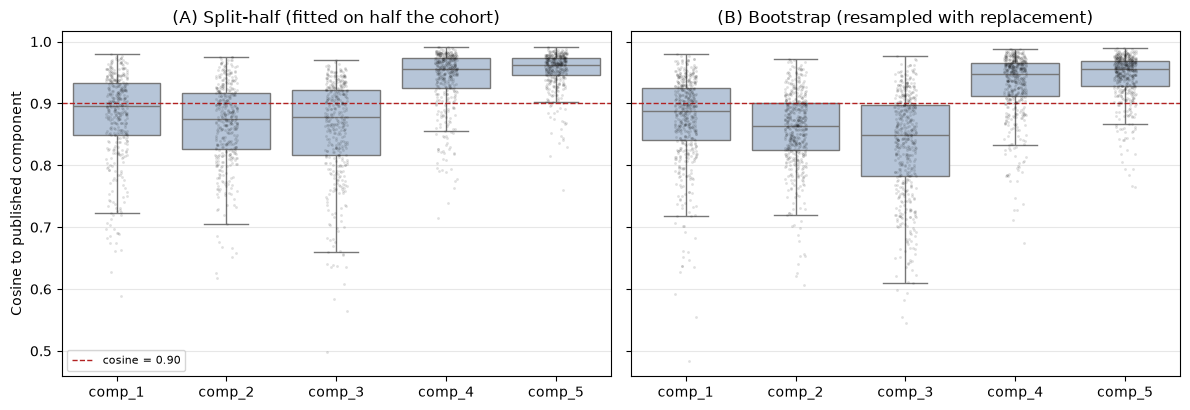

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
panels = [(recovery_df, "(A) Split-half (fitted on half the cohort)"),
          (boot_rec_df, "(B) Bootstrap (resampled with replacement)")]
for ax, (df, title) in zip(axes, panels):
    sns.boxplot(data=df, x="ref_component", y="cosine", order=COMP_LABELS,
                ax=ax, showfliers=False, color="lightsteelblue")
    sns.stripplot(data=df, x="ref_component", y="cosine", order=COMP_LABELS,
                  ax=ax, color="black", alpha=0.12, size=2)
    ax.axhline(0.90, color="firebrick", linestyle="--", linewidth=1, label="cosine = 0.90")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Cosine to published component")
    ax.grid(alpha=0.3, axis="y")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nb13_fig_recovery.png", dpi=300, bbox_inches="tight")
plt.show()

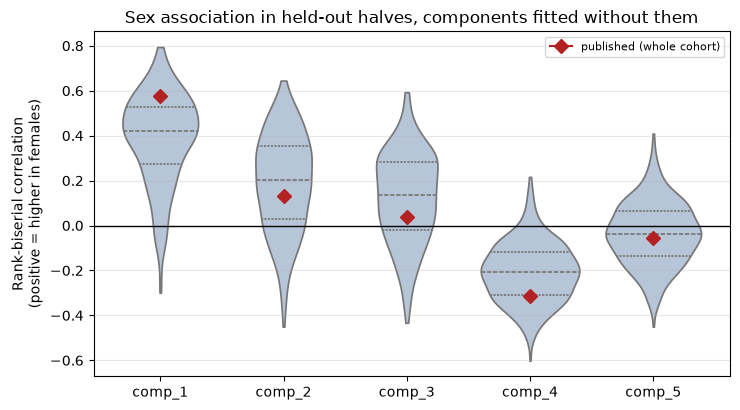

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(7.5, 4.2))
sns.violinplot(data=oos_df, x="ref_component", y="rank_biserial", order=COMP_LABELS,
               ax=ax, cut=0, inner="quartile", color="lightsteelblue")
ax.axhline(0, color="black", linewidth=1)
for i, lab in enumerate(COMP_LABELS):
    if lab in PUBLISHED_EFFECTS.index:
        ax.plot(i, PUBLISHED_EFFECTS.loc[lab, "effect_size"], marker="D", color="firebrick",
                markersize=7, zorder=5,
                label="published (whole cohort)" if i == 0 else None)
ax.set_ylabel("Rank-biserial correlation\n(positive = higher in females)")
ax.set_xlabel("")
ax.set_title("Sex association in held-out halves, components fitted without them")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nb13_fig_oos_sex.png", dpi=300, bbox_inches="tight")
plt.show()

## Part A3 — The same resampling applied to the principal component basis

Reviewer 2 observes that stability, loadings and interpretation were reported only
for the non-negative solution. Cross-initialisation stability has no counterpart in
a principal component basis, which has a unique solution, but *participant-level*
reproducibility does, and it is the comparison that matters. The split-half and
bootstrap analyses above are therefore repeated on principal components, with the
identical splits, so the two bases are compared on the same partitions of the same
cohort.

One extra step is needed, and it is itself a result. A principal axis is identified
only up to sign, so a half-sample axis may be recovered perfectly yet point the
other way. Matching therefore uses the absolute cosine, and the sign required to
align each match is recorded; without that alignment the direction of an
out-of-sample association would be meaningless. The proportion of matches that need
a sign flip is reported below. The non-negative basis requires no such step.

In [14]:
if RUN_PCA_COMPARISON:
    PC_SCORES_REF, PC_H_REF, PC_MEAN_REF = fit_pca(feature_matrix.values, PUBLISHED_K)
    PC_LABELS = [f"PC{i + 1}" for i in range(PUBLISHED_K)]
    pca_full = PCA(n_components=PUBLISHED_K, random_state=PCA_SEED).fit(feature_matrix.values)
    print(f"Reference PCA basis at k = {PUBLISHED_K}: variance explained "
          f"{np.round(pca_full.explained_variance_ratio_, 4)} "
          f"(cumulative {pca_full.explained_variance_ratio_.sum():.4f})")
    pub_pca = []
    for j, lab in enumerate(PC_LABELS):
        r, p = rb_female_higher(PC_SCORES_REF[:, j], SEX)
        pub_pca.append({"component": lab, "rank_biserial": r, "p_raw": p})
    pub_pca = pd.DataFrame(pub_pca)
    _, pf, _, _ = multipletests(pub_pca["p_raw"].values, alpha=FDR_ALPHA, method="fdr_bh")
    pub_pca["p_fdr"] = pf
    print()
    print("Full-sample PCA, per-component sex association (signs are arbitrary):")
    print(pub_pca.round(4).to_string(index=False))

Reference PCA basis at k = 5: variance explained [0.5175 0.0969 0.0433 0.0359 0.0301] (cumulative 0.7237)

Full-sample PCA, per-component sex association (signs are arbitrary):
component  rank_biserial  p_raw  p_fdr
      PC1         0.0823 0.5142 0.5142
      PC2        -0.1169 0.3530 0.5142
      PC3         0.4340 0.0005 0.0027
      PC4         0.3550 0.0047 0.0117
      PC5         0.0963 0.4445 0.5142


In [15]:
def run_split_half_pca(n_splits, seed):
    """Split-half recovery and out-of-sample sex test in the principal component basis.

    Uses the same seed, and therefore the same splits, as the non-negative run.
    """
    rng = np.random.default_rng(seed)
    rows_rec, rows_oos = [], []
    t0 = time.time()
    for s in range(n_splits):
        ia, ib = stratified_half(SEX, rng)
        for direction, (i_fit, i_test) in (("1->2", (ia, ib)), ("2->1", (ib, ia))):
            X_all = preprocess_array(feature_matrix_raw.values, fit_rows=i_fit)
            scores_fit, H_fit, mean_fit = fit_pca(X_all[i_fit], PUBLISHED_K)
            cos, idx, sgn = match_to_reference_signed(H_fit, PC_H_REF)
            scores_test = project_pca(X_all[i_test], H_fit, mean_fit)
            sex_test = SEX[i_test]
            for ci, lab in enumerate(PC_LABELS):
                rows_rec.append({"basis": "PCA", "split": s, "direction": direction,
                                 "ref_component": lab, "cosine": cos[ci],
                                 "sign_flipped": bool(sgn[ci] < 0)})
                aligned = scores_test[:, idx[ci]] * sgn[ci]
                r, p = rb_female_higher(aligned, sex_test)
                rows_oos.append({"basis": "PCA", "split": s, "direction": direction,
                                 "ref_component": lab, "matched_cosine": cos[ci],
                                 "sign_flipped": bool(sgn[ci] < 0),
                                 "rank_biserial": r, "p_raw": p})
        if (s + 1) % 25 == 0:
            print(f"  PCA: {s + 1}/{n_splits} splits ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows_rec), pd.DataFrame(rows_oos)


if RUN_PCA_COMPARISON:
    print("Split-half run in the principal component basis:")
    pca_rec_df, pca_oos_df = run_split_half_pca(N_SPLITS, RESAMPLE_SEED)
    pca_rec_df.to_csv(OUTPUT_DIR / "nb13_pca_splithalf_recovery.csv", index=False)
    pca_oos_df.to_csv(OUTPUT_DIR / "nb13_pca_splithalf_oos_sex.csv", index=False)

    pca_rec_summary = (pca_rec_df.groupby("ref_component")
                       .agg(median_cosine=("cosine", "median"),
                            q25=("cosine", lambda s: s.quantile(0.25)),
                            q75=("cosine", lambda s: s.quantile(0.75)),
                            frac_ge_090=("cosine", lambda s: (s >= 0.90).mean()),
                            frac_sign_flipped=("sign_flipped", "mean"))
                       .reindex(PC_LABELS))
    print()
    print("PCA component recovery across split halves (absolute cosine):")
    print(pca_rec_summary.round(3).to_string())
    print()
    print(f"Matches requiring a sign flip to align with the full-sample axis: "
          f"{100 * pca_rec_df['sign_flipped'].mean():.1f}% of "
          f"{len(pca_rec_df)} matches. The non-negative basis admits no such ambiguity.")

Split-half run in the principal component basis:
  PCA: 25/200 splits (0s)
  PCA: 50/200 splits (1s)
  PCA: 75/200 splits (2s)
  PCA: 100/200 splits (3s)
  PCA: 125/200 splits (3s)
  PCA: 150/200 splits (3s)
  PCA: 175/200 splits (4s)
  PCA: 200/200 splits (4s)

PCA component recovery across split halves (absolute cosine):
               median_cosine    q25    q75  frac_ge_090  frac_sign_flipped
ref_component                                                             
PC1                    0.994  0.993  0.995        1.000              0.000
PC2                    0.957  0.941  0.968        0.945              0.350
PC3                    0.804  0.699  0.874        0.138              0.238
PC4                    0.704  0.607  0.789        0.035              0.525
PC5                    0.650  0.522  0.755        0.008              0.450

Matches requiring a sign flip to align with the full-sample axis: 31.2% of 2000 matches. The non-negative basis admits no such ambiguity.


In [16]:
if RUN_PCA_COMPARISON:
    pca_oos_summary = (pca_oos_df.groupby("ref_component")
                       .agg(median_r=("rank_biserial", "median"),
                            q25_r=("rank_biserial", lambda s: s.quantile(0.25)),
                            q75_r=("rank_biserial", lambda s: s.quantile(0.75)),
                            frac_p_lt_05=("p_raw", lambda s: (s < 0.05).mean()))
                       .reindex(PC_LABELS))
    pca_oos_summary["full_sample_r"] = pub_pca.set_index("component")["rank_biserial"]
    same = []
    for lab in PC_LABELS:
        ref = pub_pca.set_index("component")["rank_biserial"][lab]
        vals = pca_oos_df.loc[pca_oos_df["ref_component"] == lab, "rank_biserial"]
        same.append(float((np.sign(vals) == np.sign(ref)).mean()))
    pca_oos_summary["frac_same_direction"] = same
    print("PCA out-of-sample sex association in held-out halves, after sign alignment:")
    print(pca_oos_summary.round(3).to_string())

PCA out-of-sample sex association in held-out halves, after sign alignment:
               median_r  q25_r  q75_r  frac_p_lt_05  full_sample_r  frac_same_direction
ref_component                                                                          
PC1               0.078 -0.004  0.160         0.008          0.082                0.740
PC2              -0.143 -0.221 -0.056         0.020         -0.117                0.870
PC3               0.383  0.281  0.464         0.560          0.434                0.990
PC4               0.286  0.085  0.433         0.378          0.355                0.822
PC5               0.108 -0.075  0.287         0.232          0.096                0.662


In [17]:
if RUN_PCA_COMPARISON:
    rng_boot_pca = np.random.default_rng(RESAMPLE_SEED + 1)
    rows = []
    t0 = time.time()
    for b in range(N_BOOT):
        take = rng_boot_pca.integers(0, N, N)
        sex_b = SEX[take]
        if (sex_b == "M").sum() < 5 or (sex_b == "F").sum() < 5:
            continue
        X_b = preprocess_array(feature_matrix_raw.values[take])
        scores_b, H_b, _ = fit_pca(X_b, PUBLISHED_K)
        cos, idx, sgn = match_to_reference_signed(H_b, PC_H_REF)
        for ci, lab in enumerate(PC_LABELS):
            r, p = rb_female_higher(scores_b[:, idx[ci]] * sgn[ci], sex_b)
            rows.append({"boot": b, "ref_component": lab, "cosine": cos[ci],
                         "sign_flipped": bool(sgn[ci] < 0), "rank_biserial": r, "p_raw": p})
        if (b + 1) % 100 == 0:
            print(f"  PCA bootstrap: {b + 1}/{N_BOOT} ({time.time() - t0:.0f}s)")
    pca_boot_df = pd.DataFrame(rows)
    pca_boot_df.to_csv(OUTPUT_DIR / "nb13_pca_bootstrap.csv", index=False)
    pca_boot_summary = (pca_boot_df.groupby("ref_component")
                        .agg(median_cosine=("cosine", "median"),
                             cosine_q025=("cosine", lambda s: s.quantile(0.025)),
                             median_r=("rank_biserial", "median"),
                             r_lo=("rank_biserial", lambda s: s.quantile(0.025)),
                             r_hi=("rank_biserial", lambda s: s.quantile(0.975)))
                        .reindex(PC_LABELS))
    print()
    print("PCA bootstrap recovery and sex effects (percentile 95% intervals):")
    print(pca_boot_summary.round(3).to_string())

  PCA bootstrap: 100/500 (2s)
  PCA bootstrap: 200/500 (3s)
  PCA bootstrap: 300/500 (5s)
  PCA bootstrap: 400/500 (7s)
  PCA bootstrap: 500/500 (9s)

PCA bootstrap recovery and sex effects (percentile 95% intervals):
               median_cosine  cosine_q025  median_r   r_lo   r_hi
ref_component                                                    
PC1                    0.994        0.985     0.087 -0.170  0.339
PC2                    0.950        0.846    -0.133 -0.448  0.190
PC3                    0.763        0.483     0.327 -0.045  0.664
PC4                    0.665        0.286     0.284 -0.190  0.702
PC5                    0.607        0.100     0.075 -0.367  0.497


## Part B1 — Refit at k = 3, 4, 5, 6

Each *k* is fitted with the same 50 initialisations and the same lowest-error selection rule
used for the published model, so k = 5 should reproduce the saved solution exactly. That
reproduction is checked, because everything downstream depends on it.

In [18]:
solutions = {}
for k in K_GRID:
    t0 = time.time()
    W_k, H_k, err_k = fit_nmf_best(feature_matrix.values, k, N_INIT_FULL, RANDOM_SEED_BASE)
    solutions[k] = {"W": W_k, "H": H_k, "err": err_k}
    print(f"k={k}: reconstruction error {err_k:.4f} ({time.time() - t0:.0f}s)")

cos_check, _ = match_to_reference(solutions[PUBLISHED_K]["H"])
print()
print(f"k={PUBLISHED_K} vs published H, cosine per component: {np.round(cos_check, 4)}")
if cos_check.min() < 0.999:
    print("WARNING: k=5 did not reproduce the published solution. Check the NMF settings.")
else:
    print("Published solution reproduced.")

k=3: reconstruction error 25.1557 (3s)
k=4: reconstruction error 23.8671 (3s)
k=5: reconstruction error 22.7852 (3s)
k=6: reconstruction error 21.7991 (3s)

k=5 vs published H, cosine per component: [1. 1. 1. 1. 1.]
Published solution reproduced.


## Part B2 — Matching components across *k*

Two directions are reported, because they answer different halves of the reviewer's question:

- **forward** (each published k = 5 component to its best match at *k*): does this component
  *persist*? If two components at k = 6 both match one k = 5 component closely, it has split.
- **reverse** (each component at *k* to its best match among the k = 5 components): does this
  component correspond to anything in the published solution, or is it a merge of several?

In [19]:
match_rows = []
for k in K_GRID:
    H_k = solutions[k]["H"]
    sim = cosine_similarity_matrix(H_REF_ARR, H_k)
    for ci, lab in enumerate(COMP_LABELS):
        j = int(np.argmax(sim[ci]))
        match_rows.append({"k": k, "direction": "forward", "from": lab,
                           "to": f"k{k}_c{j + 1}", "cosine": float(sim[ci, j])})
    for j in range(H_k.shape[0]):
        ci = int(np.argmax(sim[:, j]))
        match_rows.append({"k": k, "direction": "reverse", "from": f"k{k}_c{j + 1}",
                           "to": COMP_LABELS[ci], "cosine": float(sim[ci, j])})
    for ci, lab in enumerate(COMP_LABELS):
        for j in range(H_k.shape[0]):
            match_rows.append({"k": k, "direction": "full", "from": lab,
                               "to": f"k{k}_c{j + 1}", "cosine": float(sim[ci, j])})

match_df = pd.DataFrame(match_rows)
match_df.to_csv(OUTPUT_DIR / "nb13_rank_sweep_match.csv", index=False)

full_match = match_df[match_df["direction"] == "full"]
fwd = (match_df[match_df["direction"] == "forward"]
       .pivot(index="from", columns="k", values="cosine")
       .reindex(COMP_LABELS))
print("Best cosine from each published component to any component at k (persistence):")
print(fwd.round(3).to_string())
print()
print("Split detection: published components matched by more than one component at cosine >= 0.80")
for k in K_GRID:
    sub = full_match[(full_match["k"] == k) & (full_match["cosine"] >= 0.80)]
    counts = sub.groupby("from").size()
    multi = counts[counts > 1]
    print(f"  k={k}: {dict(multi) if len(multi) else 'none'}")
print()
print("Merge detection: components at k whose best published match is shared with another")
for k in K_GRID:
    rev = match_df[(match_df["direction"] == "reverse") & (match_df["k"] == k)]
    counts = rev.groupby("to").size()
    multi = counts[counts > 1]
    print(f"  k={k}: {dict(multi) if len(multi) else 'none'}")

Best cosine from each published component to any component at k (persistence):
k           3      4    5      6
from                            
comp_1  0.839  0.975  1.0  0.929
comp_2  0.893  0.872  1.0  0.927
comp_3  0.768  0.868  1.0  0.953
comp_4  0.991  0.996  1.0  0.982
comp_5  0.991  0.992  1.0  0.973

Split detection: published components matched by more than one component at cosine >= 0.80
  k=3: none
  k=4: none
  k=5: none
  k=6: none

Merge detection: components at k whose best published match is shared with another
  k=3: none
  k=4: none
  k=5: none
  k=6: {'comp_3': np.int64(2)}


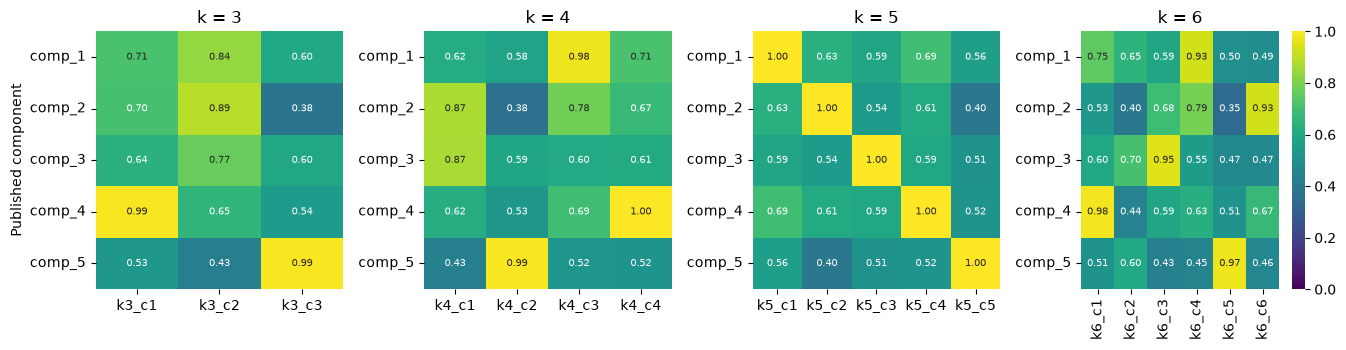

In [20]:
fig, axes = plt.subplots(1, len(K_GRID), figsize=(3.4 * len(K_GRID), 3.6))
for ax, k in zip(np.atleast_1d(axes), K_GRID):
    sub = (full_match[full_match["k"] == k]
           .pivot(index="from", columns="to", values="cosine")
           .reindex(COMP_LABELS))
    sub = sub[[f"k{k}_c{j + 1}" for j in range(solutions[k]["H"].shape[0])]]
    sns.heatmap(sub, ax=ax, cmap="viridis", vmin=0, vmax=1, annot=True, fmt=".2f",
                annot_kws={"size": 7}, cbar=(k == K_GRID[-1]))
    ax.set_title(f"k = {k}")
    ax.set_xlabel("")
    ax.set_ylabel("Published component" if k == K_GRID[0] else "")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nb13_fig_rank_match.png", dpi=300, bbox_inches="tight")
plt.show()

## Part B3 — Omnibus screen at each *k*

The full 17-variable screen from Notebook 04, re-run on each embedding with
Benjamini–Hochberg correction applied within each *k*. The statistic functions are
reproduced from Notebook 04 so the numbers are directly comparable; the logistic-regression
call is wrapped for compatibility across scikit-learn versions.

This is the slow cell. At k = 5 it should reproduce the published omnibus result for sex
(statistic 0.274, p_perm 0.0002, p_FDR 0.0034), which is checked below.

In [21]:
VAR_TYPES = {
    "Age":                               "continuous",
    "Gender":                            "binary",
    "Residential Area (Urban/Rural)":    "binary",
    "From City":                         "binary",
    "Single/NotSingle":                  "binary",
    "Education":                         "multi",
    "Field of Study":                    "multi",
    "Occupation":                        "multi",
    "# of LanguagesSpeak":               "continuous",
    "UsedToDoSport":                     "binary",
    "NowDoingSports_aWeek":              "continuous",
    "PlayingAnInstrument":               "binary",
    "History of Neurological Disorders": "binary",
    "Medication Usage":                  "binary",
    "Average Sleep Hours per Night":     "continuous",
    "Smoking (0,1,2,3)":                 "continuous",
    "Alchocol (0,1,2,3)":                "continuous",
}
VAR_TYPES = {v: t for v, t in VAR_TYPES.items() if v in metadata.columns}
print(f"{len(VAR_TYPES)} variables will be screened at each k")


def make_logreg():
    """LogisticRegression, tolerating the removal of multi_class in newer scikit-learn."""
    try:
        return LogisticRegression(max_iter=2000, multi_class="auto", solver="lbfgs")
    except TypeError:
        return LogisticRegression(max_iter=2000, solver="lbfgs")


def compute_statistic_continuous(X, y):
    """R-squared of the linear regression of y on X."""
    return LinearRegression().fit(X, y).score(X, y)


def log_likelihood_logistic(model, X, y):
    """Log-likelihood of a fitted logistic model."""
    proba = np.clip(model.predict_proba(X), 1e-12, 1 - 1e-12)
    if proba.shape[1] == 2:
        return np.sum(y * np.log(proba[:, 1]) + (1 - y) * np.log(proba[:, 0]))
    ll = 0.0
    for cls_idx, cls in enumerate(model.classes_):
        ll += np.sum(np.log(proba[y == cls, cls_idx]))
    return ll


def compute_statistic_classification(X, y):
    """McFadden pseudo-R-squared."""
    if len(np.unique(y)) < 2:
        return np.nan
    try:
        full = make_logreg().fit(X, y)
        ll_full = log_likelihood_logistic(full, X, y)
    except Exception:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    priors = counts / counts.sum()
    ll_null = sum(c * np.log(p) for c, p in zip(counts, priors))
    if ll_null == 0:
        return np.nan
    return 1 - (ll_full / ll_null)


def compute_statistic(X, y, vtype):
    """Dispatch to the statistic matching the variable's measurement scale."""
    if vtype == "continuous":
        return compute_statistic_continuous(X, y)
    if vtype in ("binary", "multi"):
        return compute_statistic_classification(X, y)
    raise ValueError(f"Unknown vtype: {vtype}")

17 variables will be screened at each k


In [22]:
def omnibus_screen(W_mat, n_perm, seed, verbose_var=None):
    """Notebook 04's omnibus permutation screen, applied to an arbitrary embedding."""
    rng = np.random.default_rng(seed)
    W_std = StandardScaler().fit_transform(W_mat)
    rows = []
    for var, vtype in VAR_TYPES.items():
        sub = pd.DataFrame({"y": metadata[var].values})
        sub["idx"] = np.arange(len(sub))
        sub = sub.dropna()
        if len(sub) < 10:
            rows.append({"variable": var, "type": vtype, "n": len(sub),
                         "observed_stat": np.nan, "p_perm": np.nan, "note": "insufficient n"})
            continue
        X_use = W_std[sub["idx"].values]
        y_raw = sub["y"].values
        if vtype != "continuous":
            y_use, _ = pd.factorize(y_raw)
        else:
            y_num = pd.to_numeric(y_raw, errors="coerce")
            valid = ~pd.isna(y_num)
            if valid.sum() < 10:
                rows.append({"variable": var, "type": vtype, "n": int(valid.sum()),
                             "observed_stat": np.nan, "p_perm": np.nan,
                             "note": "insufficient numeric data"})
                continue
            X_use = X_use[valid]
            y_use = np.asarray(y_num[valid], dtype=float)
        obs = compute_statistic(X_use, y_use, vtype)
        if np.isnan(obs):
            rows.append({"variable": var, "type": vtype, "n": len(y_use),
                         "observed_stat": np.nan, "p_perm": np.nan, "note": "statistic failed"})
            continue
        null = np.zeros(n_perm)
        y_perm = np.array(y_use, copy=True)
        for i in range(n_perm):
            rng.shuffle(y_perm)
            null[i] = compute_statistic(X_use, y_perm, vtype)
        rows.append({"variable": var, "type": vtype, "n": len(y_use), "observed_stat": obs,
                     "null_mean": float(np.mean(null)),
                     "null_95pct": float(np.percentile(null, 95)),
                     "p_perm": (np.sum(null >= obs) + 1) / (n_perm + 1), "note": ""})
        if verbose_var and var == verbose_var:
            print(f"    {var}: stat={obs:.4f}, p_perm={rows[-1]['p_perm']:.4f}")
    out = pd.DataFrame(rows)
    ok = out["p_perm"].notna()
    out["p_fdr"] = np.nan
    out["significant_fdr"] = False
    if ok.any():
        reject, p_fdr, _, _ = multipletests(out.loc[ok, "p_perm"].values,
                                            alpha=FDR_ALPHA, method="fdr_bh")
        out.loc[ok, "p_fdr"] = p_fdr
        out.loc[ok, "significant_fdr"] = reject
    return out.sort_values("p_perm")


omnibus_by_k = []
for k in K_GRID:
    print(f"k={k}: screening {len(VAR_TYPES)} variables x {N_PERMUTATIONS} permutations")
    t0 = time.time()
    res = omnibus_screen(solutions[k]["W"], N_PERMUTATIONS, PERM_SEED, verbose_var=SEX_COL)
    res.insert(0, "k", k)
    omnibus_by_k.append(res)
    survivors = list(res[res["significant_fdr"]]["variable"])
    print(f"  done in {time.time() - t0:.0f}s | {len(survivors)} variable(s) survive FDR: "
          f"{survivors if survivors else 'none'}")

omnibus_k_df = pd.concat(omnibus_by_k, ignore_index=True)
omnibus_k_df.to_csv(OUTPUT_DIR / "nb13_rank_sweep_omnibus.csv", index=False)

k=3: screening 17 variables x 5000 permutations
    Gender: stat=0.1462, p_perm=0.0008
  done in 304s | 1 variable(s) survive FDR: ['Gender']
k=4: screening 17 variables x 5000 permutations
    Gender: stat=0.2512, p_perm=0.0002
  done in 266s | 1 variable(s) survive FDR: ['Gender']
k=5: screening 17 variables x 5000 permutations
    Gender: stat=0.2742, p_perm=0.0002
  done in 274s | 1 variable(s) survive FDR: ['Gender']
k=6: screening 17 variables x 5000 permutations
    Gender: stat=0.2612, p_perm=0.0002
  done in 322s | 1 variable(s) survive FDR: ['Gender']


In [23]:
sex_by_k = omnibus_k_df[omnibus_k_df["variable"] == SEX_COL].set_index("k")
print(f"Omnibus result for {SEX_COL} across k:")
print(sex_by_k[["observed_stat", "null_mean", "null_95pct", "p_perm", "p_fdr",
                "significant_fdr"]].round(4).to_string())

pub_omni = pd.read_csv(OUTPUT_DIR / "omnibus_results.csv")
pub_row = pub_omni[pub_omni["variable"] == SEX_COL].iloc[0]
here = sex_by_k.loc[PUBLISHED_K]
print()
print(f"Published at k={PUBLISHED_K}: stat={pub_row['observed_stat']:.4f}, "
      f"p_perm={pub_row['p_perm']:.4f}, p_fdr={pub_row['p_fdr']:.4f}")
print(f"Reproduced here:     stat={here['observed_stat']:.4f}, "
      f"p_perm={here['p_perm']:.4f}, p_fdr={here['p_fdr']:.4f}")
print()
print("Any other variable surviving FDR at any k:")
others = omnibus_k_df[(omnibus_k_df["significant_fdr"]) & (omnibus_k_df["variable"] != SEX_COL)]
if len(others):
    print(others[["k", "variable", "observed_stat", "p_perm", "p_fdr"]].round(4).to_string(index=False))
else:
    print("  none")

Omnibus result for Gender across k:
   observed_stat  null_mean  null_95pct  p_perm   p_fdr  significant_fdr
k                                                                       
3         0.1462     0.0258      0.0682  0.0008  0.0136             True
4         0.2512     0.0353      0.0849  0.0002  0.0034             True
5         0.2742     0.0441      0.0967  0.0002  0.0034             True
6         0.2612     0.0535      0.1129  0.0002  0.0034             True

Published at k=5: stat=0.2742, p_perm=0.0002, p_fdr=0.0034
Reproduced here:     stat=0.2742, p_perm=0.0002, p_fdr=0.0034

Any other variable surviving FDR at any k:
  none


## Part B4 — Per-component sex follow-up at each *k*

Mann–Whitney per component with Benjamini–Hochberg correction within each *k*, exactly as in
Notebook 05. The question that matters for the manuscript's central claim: does an
**opposing pair** — at least one female-higher and one male-higher component, both surviving
correction — exist at every *k*, or only at k = 5?

In [24]:
posthoc_rows = []
for k in K_GRID:
    W_k = solutions[k]["W"]
    recs = []
    for j in range(k):
        r, p = rb_female_higher(W_k[:, j], SEX)
        recs.append({"k": k, "component": f"k{k}_c{j + 1}", "rank_biserial": r, "p_raw": p})
    sub = pd.DataFrame(recs)
    ok = sub["p_raw"].notna()
    sub["p_fdr"] = np.nan
    sub["significant_fdr"] = False
    if ok.any():
        reject, p_fdr, _, _ = multipletests(sub.loc[ok, "p_raw"].values,
                                            alpha=FDR_ALPHA, method="fdr_bh")
        sub.loc[ok, "p_fdr"] = p_fdr
        sub.loc[ok, "significant_fdr"] = reject
    sim = cosine_similarity_matrix(H_REF_ARR, solutions[k]["H"])
    sub["best_match_published"] = [COMP_LABELS[int(np.argmax(sim[:, j]))] for j in range(k)]
    sub["match_cosine"] = [float(sim[:, j].max()) for j in range(k)]
    posthoc_rows.append(sub)

posthoc_k_df = pd.concat(posthoc_rows, ignore_index=True)
posthoc_k_df.to_csv(OUTPUT_DIR / "nb13_rank_sweep_posthoc_sex.csv", index=False)

for k in K_GRID:
    sub = posthoc_k_df[posthoc_k_df["k"] == k]
    print(f"=== k = {k} ===")
    print(sub[["component", "best_match_published", "match_cosine", "rank_biserial",
               "p_raw", "p_fdr", "significant_fdr"]].round(4).to_string(index=False))
    sig = sub[sub["significant_fdr"]]
    pos = int((sig["rank_biserial"] > 0).sum())
    neg = int((sig["rank_biserial"] < 0).sum())
    if not len(sig):
        verdict = "no component survives correction"
    elif pos >= 1 and neg >= 1:
        verdict = "opposing pair present"
    else:
        verdict = "no opposing pair"
    print(f"  -> {len(sig)} component(s) survive FDR ({pos} female-higher, "
          f"{neg} male-higher): {verdict}")
    print()

=== k = 3 ===
component best_match_published  match_cosine  rank_biserial  p_raw  p_fdr  significant_fdr
    k3_c1               comp_4        0.9908        -0.2446 0.0514 0.0771            False
    k3_c2               comp_2        0.8933         0.4665 0.0002 0.0006             True
    k3_c3               comp_5        0.9910         0.0471 0.7103 0.7103            False
  -> 1 component(s) survive FDR (1 female-higher, 0 male-higher): no opposing pair

=== k = 4 ===
component best_match_published  match_cosine  rank_biserial  p_raw  p_fdr  significant_fdr
    k4_c1               comp_2        0.8725         0.1131 0.3689 0.4919            False
    k4_c2               comp_5        0.9919        -0.0238 0.8526 0.8526            False
    k4_c3               comp_1        0.9753         0.5660 0.0000 0.0000             True
    k4_c4               comp_4        0.9958        -0.2852 0.0231 0.0461             True
  -> 2 component(s) survive FDR (1 female-higher, 1 male-higher): opp

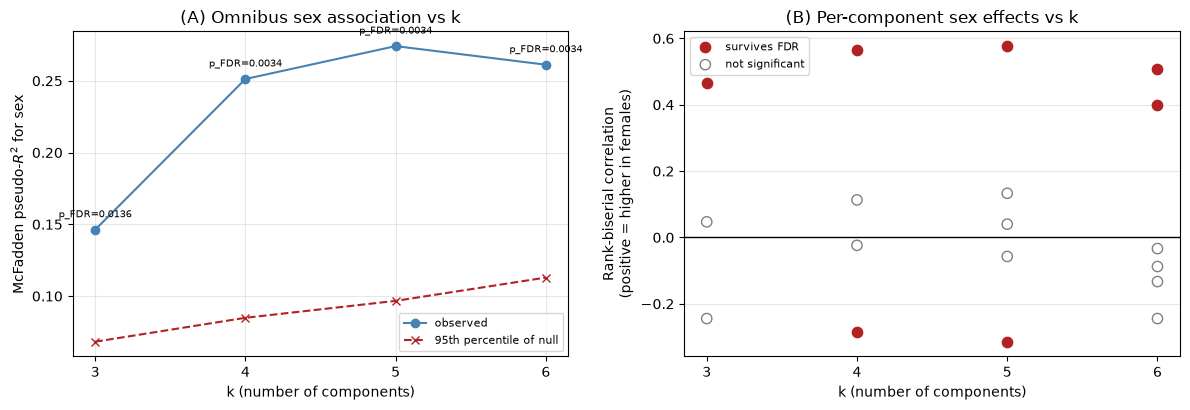

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.plot(sex_by_k.index, sex_by_k["observed_stat"], marker="o", color="steelblue",
        label="observed")
ax.plot(sex_by_k.index, sex_by_k["null_95pct"], marker="x", linestyle="--",
        color="firebrick", label="95th percentile of null")
for k in K_GRID:
    ax.annotate(f"p_FDR={sex_by_k.loc[k, 'p_fdr']:.4f}",
                (k, sex_by_k.loc[k, "observed_stat"]), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=7)
ax.set_xticks(K_GRID)
ax.set_xlabel("k (number of components)")
ax.set_ylabel("McFadden pseudo-$R^2$ for sex")
ax.set_title("(A) Omnibus sex association vs k")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
for k in K_GRID:
    sub = posthoc_k_df[posthoc_k_df["k"] == k]
    sig = sub["significant_fdr"].values.astype(bool)
    ax.scatter(np.full(int(sig.sum()), k), sub.loc[sig, "rank_biserial"], color="firebrick",
               s=55, zorder=4, label="survives FDR" if k == K_GRID[0] else None)
    ax.scatter(np.full(int((~sig).sum()), k), sub.loc[~sig, "rank_biserial"],
               facecolors="none", edgecolors="grey", s=55,
               label="not significant" if k == K_GRID[0] else None)
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(K_GRID)
ax.set_xlabel("k (number of components)")
ax.set_ylabel("Rank-biserial correlation\n(positive = higher in females)")
ax.set_title("(B) Per-component sex effects vs k")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nb13_fig_rank_sex.png", dpi=300, bbox_inches="tight")
plt.show()

## Part B5 — The same rank sweep in the principal component basis

The omnibus screen and the per-component follow-up are repeated on principal
component embeddings at each k, so that the dependence on dimensionality can be read
for both bases rather than for one.

Two structural differences are worth noting when reading the result. The principal
component embeddings are nested — the k = 3 embedding is the first three axes of the
k = 6 one — so moving up in k adds components without disturbing those already
present, whereas the non-negative solution is refitted entirely and its components
may split or merge. And the sign of each per-component effect is arbitrary, so the
count of female-higher against male-higher components carries no meaning in this
basis; only the number surviving correction does.

In [26]:
if RUN_PCA_COMPARISON:
    pca_omnibus_rows, pca_posthoc_rows = [], []
    for k in K_GRID:
        print(f"PCA k={k}: screening {len(VAR_TYPES)} variables x {N_PERMUTATIONS} permutations")
        t0 = time.time()
        scores_k, H_k, _ = fit_pca(feature_matrix.values, k)
        res = omnibus_screen(scores_k, N_PERMUTATIONS, PERM_SEED, verbose_var=SEX_COL)
        res.insert(0, "k", k)
        res.insert(0, "basis", "PCA")
        pca_omnibus_rows.append(res)
        survivors = list(res[res["significant_fdr"]]["variable"])
        print(f"  done in {time.time() - t0:.0f}s | survives FDR: "
              f"{survivors if survivors else 'none'}")

        recs = []
        for j in range(k):
            r, p = rb_female_higher(scores_k[:, j], SEX)
            recs.append({"basis": "PCA", "k": k, "component": f"k{k}_PC{j + 1}",
                         "rank_biserial": r, "p_raw": p})
        sub = pd.DataFrame(recs)
        _, pf, _, _ = multipletests(sub["p_raw"].values, alpha=FDR_ALPHA, method="fdr_bh")
        sub["p_fdr"] = pf
        sub["significant_fdr"] = sub["p_fdr"] < FDR_ALPHA
        pca_posthoc_rows.append(sub)

    pca_omnibus_df = pd.concat(pca_omnibus_rows, ignore_index=True)
    pca_posthoc_df = pd.concat(pca_posthoc_rows, ignore_index=True)
    pca_omnibus_df.to_csv(OUTPUT_DIR / "nb13_pca_rank_sweep_omnibus.csv", index=False)
    pca_posthoc_df.to_csv(OUTPUT_DIR / "nb13_pca_rank_sweep_posthoc_sex.csv", index=False)

    pca_sex_by_k = pca_omnibus_df[pca_omnibus_df["variable"] == SEX_COL].set_index("k")
    print()
    print(f"PCA omnibus result for {SEX_COL} across k:")
    print(pca_sex_by_k[["observed_stat", "null_95pct", "p_perm", "p_fdr",
                        "significant_fdr"]].round(4).to_string())
    for k in K_GRID:
        sig = pca_posthoc_df[(pca_posthoc_df["k"] == k) & pca_posthoc_df["significant_fdr"]]
        print(f"  k={k}: {len(sig)} component(s) survive correction "
              f"({', '.join(sig['component']) if len(sig) else 'none'})")

PCA k=3: screening 17 variables x 5000 permutations
    Gender: stat=0.1293, p_perm=0.0016
  done in 267s | survives FDR: ['Gender']
PCA k=4: screening 17 variables x 5000 permutations
    Gender: stat=0.2165, p_perm=0.0004
  done in 295s | survives FDR: ['Gender']
PCA k=5: screening 17 variables x 5000 permutations
    Gender: stat=0.2241, p_perm=0.0004
  done in 351s | survives FDR: ['Gender']
PCA k=6: screening 17 variables x 5000 permutations
    Gender: stat=0.2513, p_perm=0.0002
  done in 254s | survives FDR: ['Gender']

PCA omnibus result for Gender across k:
   observed_stat  null_95pct  p_perm   p_fdr  significant_fdr
k                                                            
3         0.1293      0.0673  0.0016  0.0272             True
4         0.2165      0.0845  0.0004  0.0068             True
5         0.2241      0.0968  0.0004  0.0068             True
6         0.2513      0.1136  0.0002  0.0034             True
  k=3: 1 component(s) survive correction (k3_PC3)
  k=4

## Part C — The two bases side by side

This is the table Reviewer 2's first point asks for: both embeddings on the same
features, at the same dimensionalities, under the same screen and the same
participant resampling. It is assembled from the saved outputs, so it can be run on
its own in a later session without repeating the fits above.

In [27]:
if RUN_PCA_COMPARISON:
    def _load(name, fallback):
        path = OUTPUT_DIR / name
        return pd.read_csv(path) if path.exists() else fallback

    nmf_omni = _load("nb13_rank_sweep_omnibus.csv", omnibus_k_df)
    nmf_post = _load("nb13_rank_sweep_posthoc_sex.csv", posthoc_k_df)
    nmf_rec = _load("nb13_splithalf_recovery.csv", recovery_df)
    nmf_oos = _load("nb13_splithalf_oos_sex.csv", oos_df)

    rows = []
    for k in K_GRID:
        n_s = nmf_omni[(nmf_omni["k"] == k) & (nmf_omni["variable"] == SEX_COL)].iloc[0]
        p_s = pca_sex_by_k.loc[k]
        n_sig = nmf_post[(nmf_post["k"] == k) & (nmf_post["significant_fdr"])]
        p_sig = pca_posthoc_df[(pca_posthoc_df["k"] == k) &
                               (pca_posthoc_df["significant_fdr"])]
        rows.append({
            "k": k,
            "NMF_stat": n_s["observed_stat"], "NMF_p_fdr": n_s["p_fdr"],
            "NMF_components_surviving": len(n_sig),
            "NMF_opposing_pair": bool((n_sig["rank_biserial"] > 0).any() and
                                      (n_sig["rank_biserial"] < 0).any()),
            "PCA_stat": p_s["observed_stat"], "PCA_p_fdr": p_s["p_fdr"],
            "PCA_components_surviving": len(p_sig),
        })
    side_by_side = pd.DataFrame(rows)
    side_by_side.to_csv(OUTPUT_DIR / "nb13_basis_comparison_by_k.csv", index=False)
    print("Omnibus sex association by basis and dimensionality:")
    print(side_by_side.round(4).to_string(index=False))
    print()
    print("Note: the opposing-pair column is left blank for PCA by design. A principal")
    print("axis's sign is arbitrary, so the direction of its association is not a")
    print("property of the data and the two signs cannot be read as an opposition.")

    rec_rows = []
    for lab in COMP_LABELS:
        s = nmf_rec[nmf_rec["ref_component"] == lab]["cosine"]
        o = nmf_oos[nmf_oos["ref_component"] == lab]
        rec_rows.append({"basis": "NMF", "component": lab,
                         "median_recovery_cosine": s.median(),
                         "frac_recovery_ge_090": (s >= 0.90).mean(),
                         "median_oos_r": o["rank_biserial"].median(),
                         "frac_oos_p_lt_05": (o["p_raw"] < 0.05).mean(),
                         "frac_sign_flipped": 0.0})
    for lab in PC_LABELS:
        s = pca_rec_df[pca_rec_df["ref_component"] == lab]
        o = pca_oos_df[pca_oos_df["ref_component"] == lab]
        rec_rows.append({"basis": "PCA", "component": lab,
                         "median_recovery_cosine": s["cosine"].median(),
                         "frac_recovery_ge_090": (s["cosine"] >= 0.90).mean(),
                         "median_oos_r": o["rank_biserial"].median(),
                         "frac_oos_p_lt_05": (o["p_raw"] < 0.05).mean(),
                         "frac_sign_flipped": s["sign_flipped"].mean()})
    recovery_comparison = pd.DataFrame(rec_rows)
    recovery_comparison.to_csv(OUTPUT_DIR / "nb13_basis_comparison_recovery.csv", index=False)
    print()
    print("Participant-level reproducibility by basis (200 splits, both directions):")
    print(recovery_comparison.round(3).to_string(index=False))

Omnibus sex association by basis and dimensionality:
 k  NMF_stat  NMF_p_fdr  NMF_components_surviving  NMF_opposing_pair  PCA_stat  PCA_p_fdr  PCA_components_surviving
 3    0.1462     0.0136                         1              False    0.1293     0.0272                         1
 4    0.2512     0.0034                         2               True    0.2165     0.0068                         2
 5    0.2742     0.0034                         2               True    0.2241     0.0068                         2
 6    0.2612     0.0034                         2              False    0.2513     0.0034                         2

Note: the opposing-pair column is left blank for PCA by design. A principal
axis's sign is arbitrary, so the direction of its association is not a
property of the data and the two signs cannot be read as an opposition.

Participant-level reproducibility by basis (200 splits, both directions):
basis component  median_recovery_cosine  frac_recovery_ge_090  median_oo

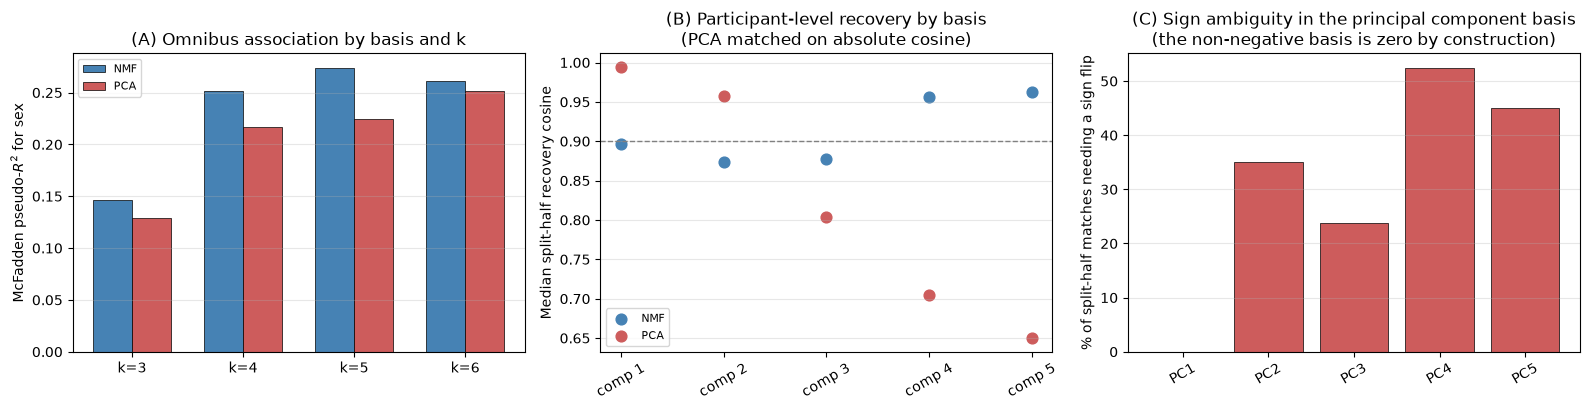

In [28]:
if RUN_PCA_COMPARISON:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

    ax = axes[0]
    w = 0.35
    x = np.arange(len(K_GRID))
    ax.bar(x - w / 2, side_by_side["NMF_stat"], width=w, label="NMF",
           color="steelblue", edgecolor="black", linewidth=0.5)
    ax.bar(x + w / 2, side_by_side["PCA_stat"], width=w, label="PCA",
           color="indianred", edgecolor="black", linewidth=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels([f"k={k}" for k in K_GRID])
    ax.set_ylabel("McFadden pseudo-$R^2$ for sex")
    ax.set_title("(A) Omnibus association by basis and k")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")

    ax = axes[1]
    for basis, colour in (("NMF", "steelblue"), ("PCA", "indianred")):
        sub = recovery_comparison[recovery_comparison["basis"] == basis]
        ax.scatter(range(len(sub)), sub["median_recovery_cosine"], s=60,
                   color=colour, label=basis)
    ax.axhline(0.90, color="grey", linestyle="--", linewidth=1)
    ax.set_xticks(range(PUBLISHED_K))
    ax.set_xticklabels([f"comp {i + 1}" for i in range(PUBLISHED_K)], rotation=30)
    ax.set_ylabel("Median split-half recovery cosine")
    ax.set_title("(B) Participant-level recovery by basis\n(PCA matched on absolute cosine)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")

    ax = axes[2]
    sub = recovery_comparison[recovery_comparison["basis"] == "PCA"]
    ax.bar(range(len(sub)), 100 * sub["frac_sign_flipped"], color="indianred",
           edgecolor="black", linewidth=0.5)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub["component"], rotation=30)
    ax.set_ylabel("% of split-half matches needing a sign flip")
    ax.set_title("(C) Sign ambiguity in the principal component basis\n"
                 "(the non-negative basis is zero by construction)")
    ax.grid(alpha=0.3, axis="y")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "nb13_fig_basis_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()

## Summary for the response letter

In [29]:
lines = []


def w(s=""):
    """Print and record a summary line."""
    print(s)
    lines.append(s)


w("=" * 72)
w("NOTEBOOK 13 SUMMARY - reproducibility across participants and rank selection")
w("=" * 72)
w(f"N = {N} participants ({(SEX == 'M').sum()} male, {(SEX == 'F').sum()} female)")
w("")
w("PART A1 - SPLIT-HALF (fit on half the cohort, transform refitted within the half)")
w(f"  {N_SPLITS} splits x 2 directions")
for lab in COMP_LABELS:
    r = rec_summary.loc[lab]
    w(f"  {lab}: cosine median {r['median']:.3f} (IQR {r['q25']:.3f}-{r['q75']:.3f}), "
      f"{100 * r['frac_ge_090']:.0f}% of fits >= 0.90")
w("")
w("PART A1 - OUT-OF-SAMPLE SEX ASSOCIATION (held-out halves only)")
for lab in COMP_LABELS:
    r = oos_summary.loc[lab]
    w(f"  {lab}: median r {r['median_r']:+.3f} (IQR {r['q25_r']:+.3f} to {r['q75_r']:+.3f}), "
      f"p<0.05 in {100 * r['frac_p_lt_05']:.0f}% of held-out halves, "
      f"direction matches published in {100 * r['frac_same_direction']:.0f}%")
w("")
w("PART A2 - BOOTSTRAP (resamples with replacement)")
for lab in COMP_LABELS:
    r = boot_summary.loc[lab]
    w(f"  {lab}: cosine median {r['median_cosine']:.3f} (2.5th pct {r['cosine_q025']:.3f}); "
      f"sex r {r['median_r']:+.3f} [{r['r_ci_lo']:+.3f}, {r['r_ci_hi']:+.3f}]"
      f"{' excludes 0' if r['r_ci_excludes_0'] else ''}")
w("")
w("PART B - RANK SELECTION")
for k in K_GRID:
    s = sex_by_k.loc[k]
    sub = posthoc_k_df[posthoc_k_df["k"] == k]
    sig = sub[sub["significant_fdr"]]
    pos = int((sig["rank_biserial"] > 0).sum())
    neg = int((sig["rank_biserial"] < 0).sum())
    w(f"  k={k}: omnibus stat {s['observed_stat']:.3f}, p_perm {s['p_perm']:.4f}, "
      f"p_FDR {s['p_fdr']:.4f}{' *' if s['significant_fdr'] else ''} | "
      f"{len(sig)} component(s) survive ({pos} female-higher, {neg} male-higher)")
w("")
w("  Persistence of the published components across k (best cosine):")
for lab in COMP_LABELS:
    row = fwd.loc[lab]
    w(f"    {lab}: " + ", ".join(f"k{k}={row[k]:.3f}" for k in K_GRID))

if RUN_PCA_COMPARISON:
    w("")
    w("PART A3 / B5 / C - PRINCIPAL COMPONENT BASIS, SAME SPLITS AND SAME SCREEN")
    w("  Split-half recovery (absolute cosine) and out-of-sample association:")
    for lab in PC_LABELS:
        r = pca_rec_summary.loc[lab]
        o = pca_oos_summary.loc[lab]
        w(f"    {lab}: cosine median {r['median_cosine']:.3f} "
          f"({100 * r['frac_ge_090']:.0f}% >= 0.90), sign flip needed in "
          f"{100 * r['frac_sign_flipped']:.0f}% of matches; out-of-sample r "
          f"{o['median_r']:+.3f}, p<0.05 in {100 * o['frac_p_lt_05']:.0f}%, "
          f"direction matches full sample in {100 * o['frac_same_direction']:.0f}%")
    w("")
    w("  Omnibus association by basis and k:")
    for _, r in side_by_side.iterrows():
        w(f"    k={int(r['k'])}: NMF stat {r['NMF_stat']:.3f} (p_FDR {r['NMF_p_fdr']:.4f}), "
          f"{int(r['NMF_components_surviving'])} component(s) survive"
          f"{', opposing pair' if r['NMF_opposing_pair'] else ''} | "
          f"PCA stat {r['PCA_stat']:.3f} (p_FDR {r['PCA_p_fdr']:.4f}), "
          f"{int(r['PCA_components_surviving'])} component(s) survive")
    w("")
    w(f"  Sign flips needed across all PCA split-half matches: "
      f"{100 * pca_rec_df['sign_flipped'].mean():.1f}% of {len(pca_rec_df)}. "
      "Zero in the non-negative basis by construction.")
w("")
w("=" * 72)

with open(OUTPUT_DIR / "nb13_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print()
print(f"Saved {OUTPUT_DIR / 'nb13_summary.txt'}")

NOTEBOOK 13 SUMMARY - reproducibility across participants and rank selection
N = 86 participants (44 male, 42 female)

PART A1 - SPLIT-HALF (fit on half the cohort, transform refitted within the half)
  200 splits x 2 directions
  comp_1: cosine median 0.896 (IQR 0.849-0.934), 47% of fits >= 0.90
  comp_2: cosine median 0.874 (IQR 0.826-0.917), 34% of fits >= 0.90
  comp_3: cosine median 0.878 (IQR 0.817-0.922), 40% of fits >= 0.90
  comp_4: cosine median 0.956 (IQR 0.926-0.973), 84% of fits >= 0.90
  comp_5: cosine median 0.963 (IQR 0.945-0.974), 94% of fits >= 0.90

PART A1 - OUT-OF-SAMPLE SEX ASSOCIATION (held-out halves only)
  comp_1: median r +0.420 (IQR +0.274 to +0.528), p<0.05 in 65% of held-out halves, direction matches published in 95%
  comp_2: median r +0.201 (IQR +0.029 to +0.356), p<0.05 in 26% of held-out halves, direction matches published in 79%
  comp_3: median r +0.135 (IQR -0.020 to +0.284), p<0.05 in 12% of held-out halves, direction matches published in 72%
  com